# 01 · URFD dataset exploration

**Project:** From Pixels to Graphs, human fall detection with graph ML.
**Goal of this notebook:** understand the UR Fall Detection dataset (URFD) before building skeleton graphs:
what's in it, how it is labeled, how balanced it is, and whether MediaPipe can extract usable skeletons from its frames.

Data is downloaded with `python scripts/download_urfd.py` into `data/raw/urfd/` (camera 0 only: cam1 is ceiling-mounted, which suits depth methods but not 2D pose estimation).

Citation: B. Kwolek, M. Kepski, *Human fall detection on embedded platform using depth maps and wireless accelerometer*, CMPB 117(3), 2014. License CC BY-NC-SA 4.0.

In [13]:
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
import networkx as nx

sns.set_theme(style="whitegrid", context="notebook")
ROOT = Path("..") / "data" / "raw" / "urfd"
FEATS = ["HeightWidthRatio", "MajorMinorRatio", "BBoxOccupancy", "MaxStdXZ", "HHmaxRatio", "H", "D", "P40"]
LABELS = {-1: "not lying", 0: "transition", 1: "lying"}
PAL = {"not lying": "#4C9BE8", "transition": "#F2A541", "lying": "#D9534F"}

## 1. Inventory: sequences and frames

In [14]:
def frames_of(seq):
    return sorted((ROOT / "rgb" / seq).rglob("*.png"))

seqs = sorted(p.name for p in (ROOT / "rgb").iterdir() if p.is_dir())
inv = pd.DataFrame({"seq": seqs})
inv["kind"] = inv.seq.str.split("-").str[0]
inv["n_frames"] = inv.seq.map(lambda s: len(frames_of(s)))
h, w = cv2.imread(str(frames_of(seqs[0])[0])).shape[:2]
print(f"{len(inv)} sequences, {inv.n_frames.sum():,} RGB frames at {w}x{h}, 30 fps")
inv.groupby("kind").n_frames.agg(["count", "sum", "mean", "min", "max"]).round(1)

70 sequences, 11,936 RGB frames at 640x480, 30 fps


,count,sum,mean,min,max
kind,,,,,
adl,40,8941,223.5,70,400
fall,30,2995,99.8,55,215


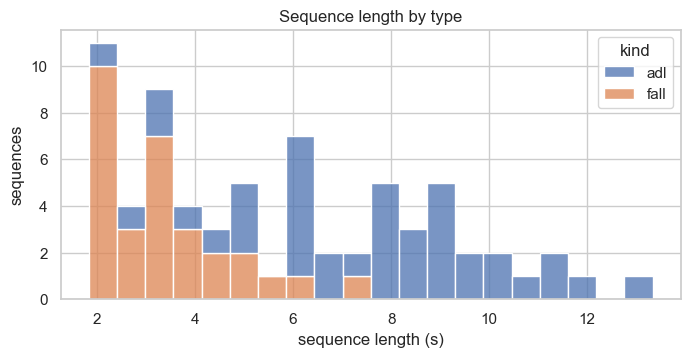

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(inv, x=inv.n_frames / 30, hue="kind", bins=20, multiple="stack", ax=ax)
ax.set(xlabel="sequence length (s)", ylabel="sequences", title="Sequence length by type")
plt.show()

## 2. Frame-level labels

`urfall-cam0-*.csv` gives, per frame: sequence, frame number, label (-1 not lying, 0 transition, 1 lying on the floor) and 8 depth-based features the authors used.

In [16]:
lab = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None) for k in ["falls", "adls"]], ignore_index=True)
lab.columns = ["seq", "frame", "label"] + FEATS
lab["kind"] = lab.seq.str.split("-").str[0]
lab["label_name"] = lab.label.map(LABELS)

cov = lab.groupby("seq").frame.agg(n_labeled="count", last="max").join(inv.set_index("seq").n_frames)
cov["coverage"] = (cov.n_labeled / cov.n_frames).round(2)
print("labeled frames:", len(lab), "| sequences with labels:", cov.shape[0])
print("coverage of RGB frames by labels:", cov.coverage.describe().round(2).to_dict())
pd.crosstab(lab.kind, lab.label_name, margins=True)

labeled frames: 11544 | sequences with labels: 70
coverage of RGB frames by labels: {'count': 70.0, 'mean': 0.98, 'std': 0.04, 'min': 0.77, '25%': 0.97, '50%': 1.0, '75%': 1.0, 'max': 1.0}


label_name,lying,not lying,transition,All
kind,,,,
adl,1470,6260,819,8549
fall,903,1192,900,2995
All,2373,7452,1719,11544


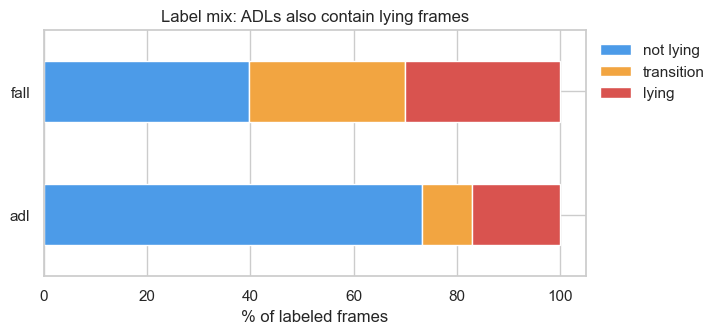

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
(pd.crosstab(lab.kind, lab.label_name, normalize="index") * 100)[list(PAL)].plot.barh(
    stacked=True, color=list(PAL.values()), ax=ax)
ax.set(xlabel="% of labeled frames", ylabel="", title="Label mix: ADLs also contain lying frames")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
plt.show()

### Label timelines: what a fall looks like vs an ADL

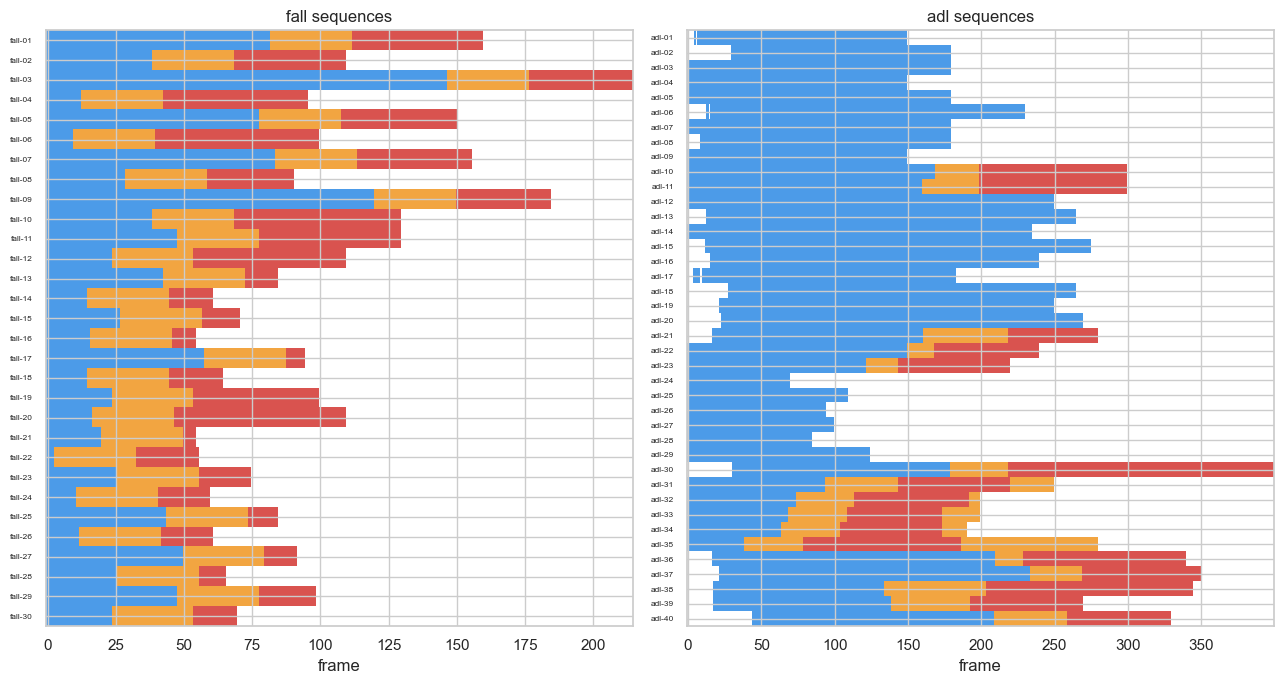

In [18]:
def timeline(kind, ax):
    sub = sorted(lab[lab.kind == kind].seq.unique())
    cmap = {-1: 0, 0: 1, 1: 2}
    maxf = lab[lab.kind == kind].frame.max()
    M = np.full((len(sub), maxf), np.nan)
    for i, s in enumerate(sub):
        d = lab[lab.seq == s]
        M[i, d.frame.values - 1] = d.label.map(cmap).values
    from matplotlib.colors import ListedColormap
    ax.imshow(M, aspect="auto", cmap=ListedColormap(list(PAL.values())), interpolation="nearest")
    ax.set(yticks=range(len(sub)), yticklabels=sub, xlabel="frame", title=f"{kind} sequences")
    ax.tick_params(axis="y", labelsize=6)

fig, axs = plt.subplots(1, 2, figsize=(13, 7))
timeline("fall", axs[0]); timeline("adl", axs[1])
plt.tight_layout(); plt.show()

In [19]:
# Phase durations inside falls (how many frames does the actual fall last?)
def runs(d):
    r = (d.label != d.label.shift()).cumsum().rename("run")
    return d.groupby(r).agg(label=("label", "first"), n=("label", "size"))
ph = pd.concat({s: runs(d.sort_values("frame")) for s, d in lab.groupby("seq")}).reset_index(level=0).rename(columns={"level_0": "seq"})
ph["kind"] = ph.seq.str.split("-").str[0]
ph["seconds"] = ph.n / 30
ph.groupby(["kind", "label"]).seconds.describe()[["count", "mean", "min", "max"]].round(2)

count  mean   min   max
kind label                         
adl  -1      40.0  5.22  1.30  8.77
      0      21.0  1.30  0.27  3.10
      1      16.0  3.06  2.03  6.03
fall -1      30.0  1.32  0.10  4.90
      0      30.0  1.00  1.00  1.00
      1      30.0  1.00  0.17  2.10

## 3. What the frames look like

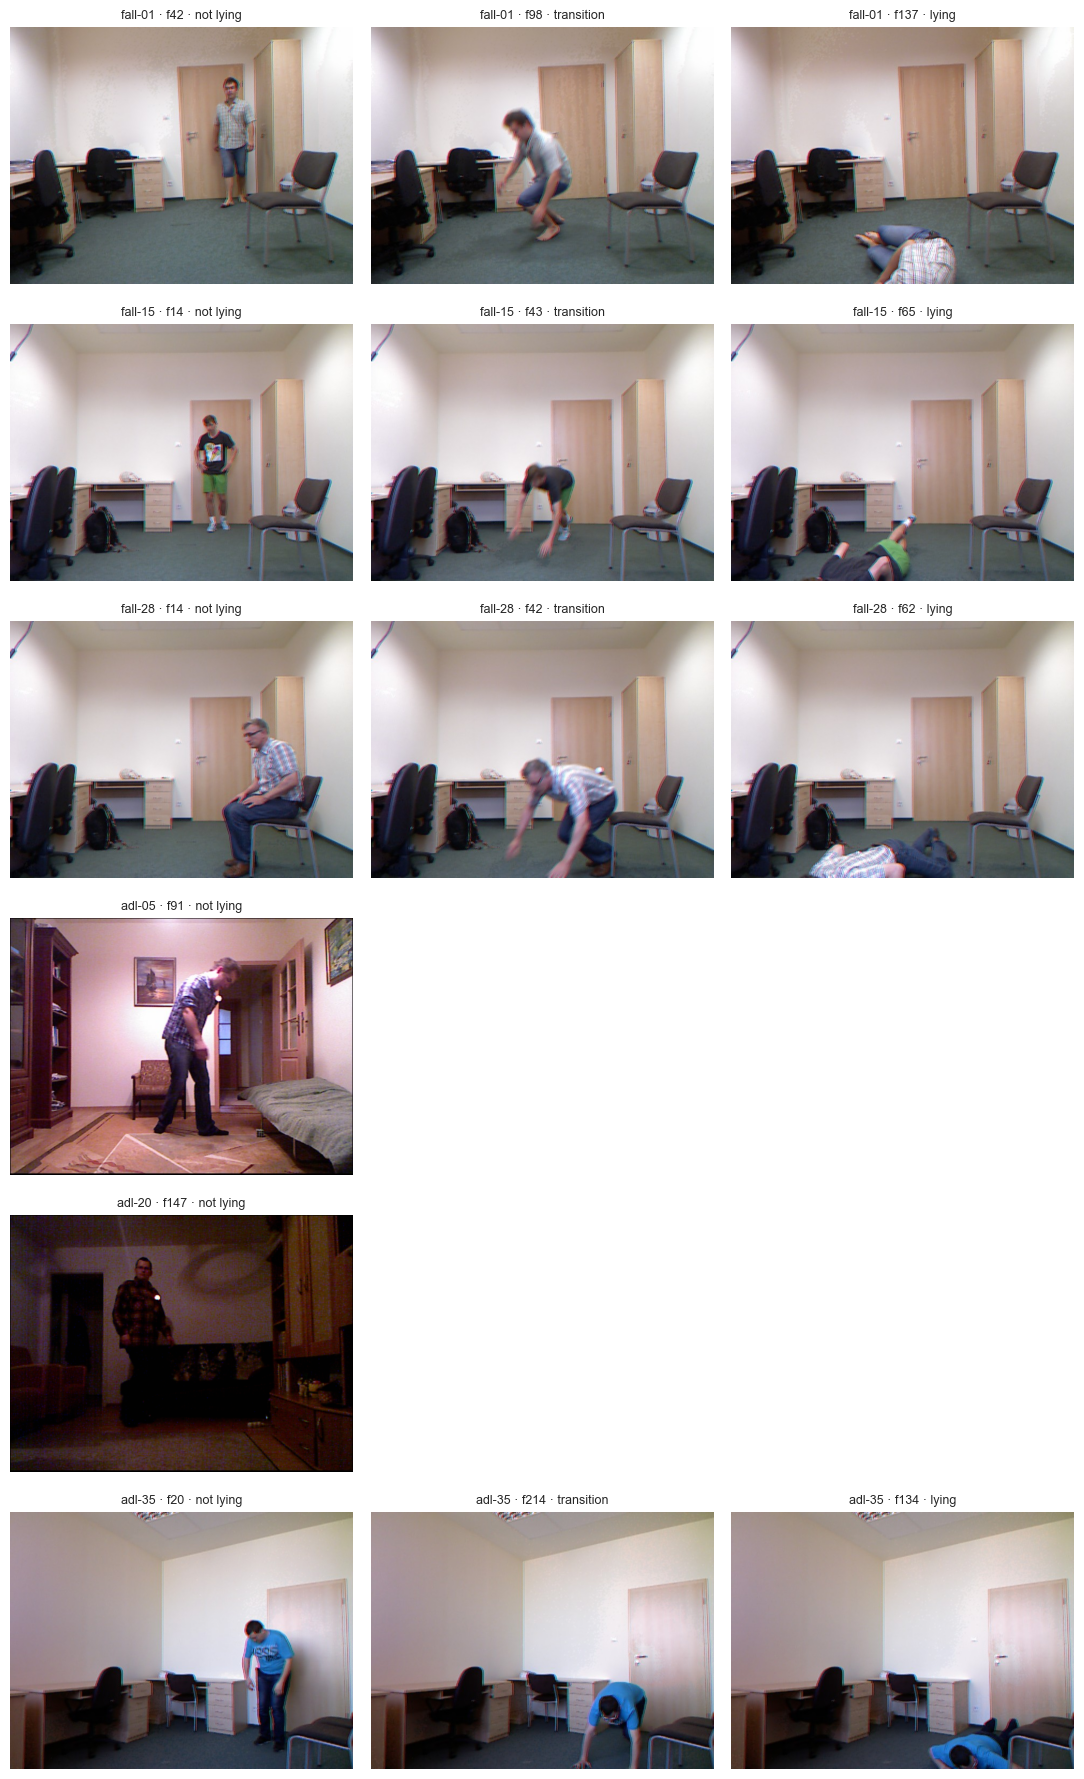

In [20]:
def phase_frames(seq):
    d = lab[lab.seq == seq]
    out = []
    for l in [-1, 0, 1]:
        f = d[d.label == l].frame
        if len(f): out.append((l, int(f.iloc[len(f) // 2])))
    return out

show = ["fall-01", "fall-15", "fall-28", "adl-05", "adl-20", "adl-35"]
fig, axs = plt.subplots(len(show), 3, figsize=(11, 3 * len(show)))
for r, s in enumerate(show):
    for c in range(3): axs[r, c].axis("off")
    for c, (l, fr) in enumerate(phase_frames(s)):
        img = cv2.cvtColor(cv2.imread(str(frames_of(s)[fr - 1])), cv2.COLOR_BGR2RGB)
        axs[r, c].imshow(img); axs[r, c].set_title(f"{s} · f{fr} · {LABELS[l]}", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Sensor side: accelerometer around the fall

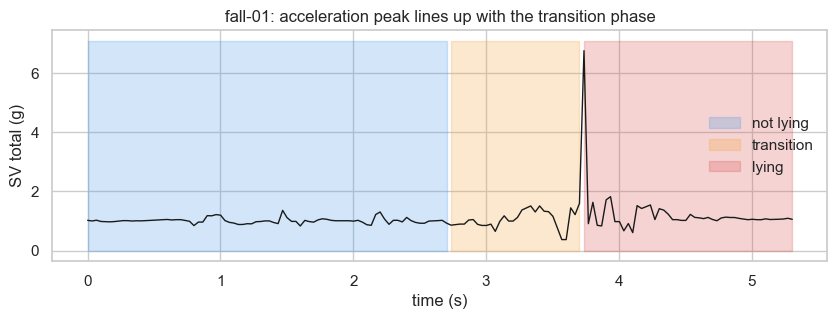

In [21]:
s = "fall-01"
sync = pd.read_csv(ROOT / "sync" / f"{s}-data.csv", header=None, names=["frame", "ms", "SV"])
d = sync.merge(lab[lab.seq == s][["frame", "label"]], on="frame", how="left")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(d.ms / 1000, d.SV, color="k", lw=1)
for l, n in LABELS.items():
    m = d.label == l
    ax.fill_between(d.ms / 1000, 0, d.SV.max() * 1.05, where=m, color=PAL[n], alpha=.25, label=n, step="mid")
ax.set(xlabel="time (s)", ylabel="SV total (g)", title=f"{s}: acceleration peak lines up with the transition phase")
ax.legend(frameon=False); plt.show()

## 5. Can MediaPipe see the person? (pose extraction feasibility)

Run MediaPipe Pose Landmarker (full model, 33 joints) on every 5th frame of every sequence and measure the detection rate per label.
Lying people are the hard case for 2D pose models, and lying is exactly the class we care about.

In [22]:
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

opts = vision.PoseLandmarkerOptions(base_options=BaseOptions(model_asset_path="../models/pose_landmarker_full.task"),
                                    running_mode=vision.RunningMode.IMAGE, num_poses=1)
det = vision.PoseLandmarker.create_from_options(opts)

lab_idx = lab.set_index(["seq", "frame"]).label
rows = []
for s in seqs:
    fs = frames_of(s)
    for i in range(0, len(fs), 5):
        img = cv2.cvtColor(cv2.imread(str(fs[i])), cv2.COLOR_BGR2RGB)
        res = det.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=img))
        ok = len(res.pose_landmarks) > 0
        vis = np.mean([p.visibility for p in res.pose_landmarks[0]]) if ok else np.nan
        rows.append((s, i + 1, ok, vis, lab_idx.get((s, i + 1), np.nan)))
pose = pd.DataFrame(rows, columns=["seq", "frame", "detected", "mean_vis", "label"])
pose["kind"] = pose.seq.str.split("-").str[0]
pose["label_name"] = pose.label.map(LABELS).fillna("unlabeled")
print(f"{len(pose)} frames tested, overall detection rate {pose.detected.mean():.1%}")
pose.groupby(["kind", "label_name"]).agg(frames=("detected", "size"), detection_rate=("detected", "mean"),
                                         mean_visibility=("mean_vis", "mean")).round(3)

2396 frames tested, overall detection rate 74.2%


frames  detection_rate  mean_visibility
kind label_name                                         
adl  lying          292           0.414            0.715
     not lying     1248           0.789            0.877
     transition     163           0.914            0.801
     unlabeled       86           0.081            0.820
fall lying          178           0.567            0.804
     not lying      249           0.976            0.908
     transition     180           0.950            0.833

sequences with lowest detection rate:
seq
adl-23    0.39
adl-38    0.43
adl-22    0.44
adl-19    0.44
adl-30    0.50
adl-13    0.51
adl-18    0.51
adl-21    0.52


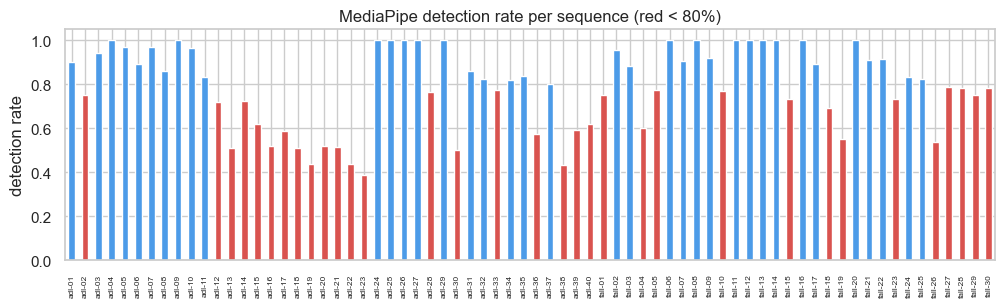

In [23]:
worst = pose.groupby("seq").detected.mean().sort_values()
print("sequences with lowest detection rate:"); print(worst.head(8).round(2).to_string())
fig, ax = plt.subplots(figsize=(12, 3))
worst.sort_index().plot.bar(ax=ax, color=["#D9534F" if v < .8 else "#4C9BE8" for v in worst.sort_index()])
ax.set(ylabel="detection rate", xlabel="", title="MediaPipe detection rate per sequence (red < 80%)")
ax.tick_params(axis="x", labelsize=6); plt.show()

## 6. From skeleton to graph

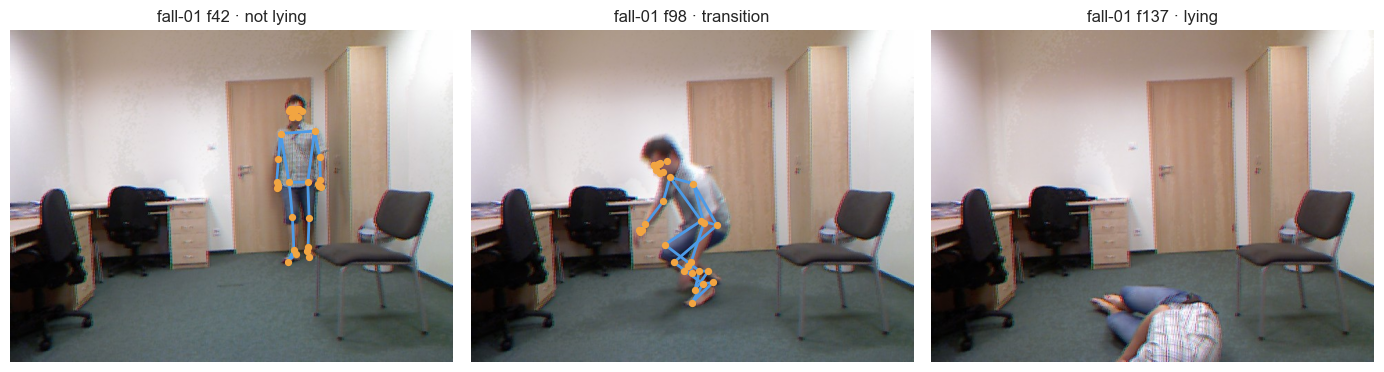

skeleton graph: 33 nodes, 35 edges, avg degree 2.12
connected components: [[11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [0, 1, 2, 3, 4, 5, 6, 7, 8], [9, 10]]
diameter of the body component: 8
-> the face is not linked to the body: we must add an edge (nose to shoulder midpoint) or drop face joints.


In [24]:
EDGES = [(c.start, c.end) for c in vision.PoseLandmarksConnections.POSE_LANDMARKS]
s = "fall-01"
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (l, fr) in zip(axs, phase_frames(s)):
    img = cv2.cvtColor(cv2.imread(str(frames_of(s)[fr - 1])), cv2.COLOR_BGR2RGB)
    res = det.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=img))
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{s} f{fr} · {LABELS[l]}")
    if res.pose_landmarks:
        P = np.array([[p.x * img.shape[1], p.y * img.shape[0]] for p in res.pose_landmarks[0]])
        G = nx.Graph(EDGES)
        nx.draw_networkx(G, pos={i: P[i] for i in G}, ax=ax, node_size=18, with_labels=False,
                         node_color="#F2A541", edge_color="#4C9BE8", width=2)
plt.tight_layout(); plt.show()
G = nx.Graph(EDGES)
print(f"skeleton graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, "
      f"avg degree {2 * G.number_of_edges() / G.number_of_nodes():.2f}")
comps = sorted(nx.connected_components(G), key=len, reverse=True)
print(f"connected components: {[sorted(c) for c in comps]}")
print(f"diameter of the body component: {nx.diameter(G.subgraph(comps[0]))}")
print("-> the face is not linked to the body: we must add an edge (nose to shoulder midpoint) or drop face joints.")

## 7. Takeaways for the project

**Task:** classify each sequence as fall or no fall. 70 sequences: 30 falls, 40 ADLs; 11,936 RGB frames, 11,544 of them labeled.

1. **Sequence length gives the answer away.** Falls average 100 frames (55 to 215), ADLs 224 (70 to 400). A model given full sequences can learn "short = fall". Use fixed-length clips and never use length as a feature.
2. **Lying is not falling.** ADLs contain 1,470 lying frames (more than the 903 in falls). The model has to learn the movement, not the final pose.
3. **Falls are short and labeled the same way.** Every fall has a 30-frame (1.0 s) transition. Before it, the person is standing for 1.3 s on average (as little as 0.1 s); after it, lying for 1.0 s on average (as little as 0.17 s). Clips of 45 frames (1.5 s) fit every fall sequence; fall clips are those that contain the transition.
4. **Pose detection is the main risk.** MediaPipe (IMAGE mode, every 5th frame) found a person in 74.2% of frames: 95 to 98% for standing and transition in falls, but only 41% for ADL lying and 57% for fall lying. The 8 worst sequences are all ADLs (39 to 52%). Next: try VIDEO mode, a lower confidence threshold, rotating or cropping frames; keep the depth-feature baseline as a fallback.
5. **The skeleton graph needs one fix.** 33 joints and 35 edges form 3 separate parts: the face is not connected to the body. Add a nose to shoulder-midpoint edge, or drop the face joints.
6. **Use labels with care.** 392 RGB frames have no label (coverage per sequence is 77% to 100%); clips must skip them. The `label` column must never be a model input.

**Next step:** fixed sequence-level cross-validation splits (`scripts/make_splits.py`), then the depth-feature baseline.